In [85]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import var, plot_implicit
from matplotlib.tri import Triangulation
import multiprocessing as mp
from scipy.integrate import tplquad
from matplotlib import rc
from scipy.special import gamma

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 15})

# test \pi

In [3]:
def pi(N_max, case_random=True):
    n = 0 #št zadetkov
    N = 0 #št klicev
    if case_random:
        #xx = np.random.random(int(np.sqrt(N_max)))
        #yy = np.random.random(int(np.sqrt(N_max)))
        while N < N_max:
                x = np.random.random()
                y = np.random.random()
                r = x*x + y*y #kvadrat
                if r <= 1: #znotraj kroga
                    n += 1
                    N += 1
                    #plt.plot(x,y, 'r.')
                else:
                    N += 1
                    #plt.plot(x,y, 'y.')
    else:
        xx = np.linspace(0, 1 , int(np.sqrt(N_max)))
        yy = np.linspace(0, 1 , int(np.sqrt(N_max)))
        for x in xx:
            for y in yy:
                r = x*x + y*y #kvadrat
                if r <= 1: #znotraj kroga
                    n += 1
                    N += 1
                    #plt.plot(x,y, 'r.')
                else:
                    N += 1
                    #plt.plot(x,y, 'y.')
    pi = 4 * n/N
    napaka = pi - np.pi 
    napaka = pi/N *np.sqrt(n-n**2/N)
    # print(f'pi = {pi}, napaka = {napaka}')
    # print(f'število točk: {N_max}')
    # plt.plot((0,0,1,1,0),(0,1,1,0,0),'k')
    # x_=np.linspace(0,1)
    # plt.plot(x_,np.sqrt(1-x_**2),'b')
    # plt.xticks([])
    # plt.yticks([])
    # #plt.savefig('slike/pi_mreža.pdf',bbox_inches='tight')
    # plt.show()
    return pi, napaka
pi(1000000, True)

(3.142348, 0.0012896651971071775)

In [54]:
PI=[]
napaka=[]
PI_=[]
napaka_=[]
N0=np.logspace(4, 7,20)
for N in N0:
    pii, ni= pi(N,True)
    PI.append(pii)
    napaka.append(ni)
    pii, ni= pi(N,False)
    PI_.append(pii)
    napaka_.append(ni)

In [55]:
plt.errorbar(N0,PI,np.abs(napaka),fmt='.-',capsize=3,label='random grid')
plt.errorbar(N0,PI_,np.abs(napaka_),fmt='.-',capsize=3,label='regular grid')
plt.axhline(y=np.pi,color='k')
plt.legend()
plt.xscale('log')
plt.xlabel('iteracije')
plt.ylabel('$\pi$')
#plt.savefig('slike/pi_napaka.pdf',bbox_inches='tight')

NameError: name 'N0' is not defined

# 1.nal

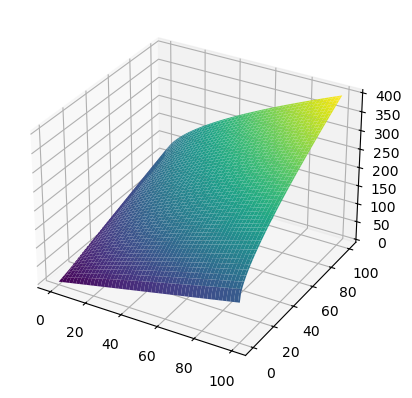

In [3]:
def z(x,y):
    return (np.sqrt(x) + np.sqrt(y))**2
x=np.linspace(0,100,100)
y=np.linspace(0,100,100)
xx, yy = np.meshgrid(x,y)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(xx, yy, z(xx,yy), cmap='viridis')

In [4]:
def telo(x,y,z,p=0):
    return np.sqrt(abs(x)) + np.sqrt(abs(y)) + np.sqrt(abs(z))**p

# x=np.linspace(0,100,100)
# data=[]
# for i in x:
#     for j in x:
#         for k in x:
#             if telo(i,j,k) == 1:
#                 data.append(i,j,k)
# data
#plt.plot(data[0], data[1])

In [5]:
def masa(N_max, p=0): #oktant poenostavitev
    n = 0 #št zadetkov
    N = 0 #št klicev
    m = 0 #masa
    napaka = 0

    while N < N_max:
        x = np.random.random()
        y = np.random.random()
        z = np.random.random()
        r = np.sqrt(x) + np.sqrt(y) + np.sqrt(z)
        if r <= 1: #znotraj
            n += 1
            N += 1
            m += r**p
            napaka += (r**p)**2
        else:
            N += 1
    napaka = np.sqrt(8*napaka/N - (8*m/N)**2)/np.sqrt(N)
    return 8*m/N, napaka
masa(100000, 0)

(0.08696, 0.0008910553203926229)

In [6]:
def masa2(N_max, p=0):
    n = 0 #št zadetkov
    N = 0 #št klicev
    m = 0 #masa

    x = np.random.random(size=int(N_max**(1/3)))
    y = np.random.random(size=int(N_max**(1/3)))
    z = np.random.random(size=int(N_max**(1/3)))

    # x = np.linspace(0, 1, int(N_max**(1/3))) #regular grid
    # y = np.linspace(0, 1, int(N_max**(1/3)))
    # z = np.linspace(0, 1, int(N_max**(1/3)))

    for i in x:
        for j in y:
            for k in z:
                r = np.sqrt(i) + np.sqrt(j) + np.sqrt(k)
                if r <= 1: #znotraj
                    #n += 1
                    N += 1
                    m += r**p
                else:
                    N += 1
    return 8*m/N
masa2(1000000, 0)

0.11181707906531904

In [7]:
import numpy as np
import multiprocessing as mp
def monte_carlo_chunk(chunk_size,p=0):
    n = 0
    N = 0
    m = 0
    print('process')
    np.random.seed()
    x = np.random.random(size=chunk_size)
    y = np.random.random(size=chunk_size)
    z = np.random.random(size=chunk_size)

    for i, j, k in zip(x, y, z):
        r = np.sqrt(i) + np.sqrt(j) + np.sqrt(k)
        if r <= 1:
            N += 1
            m += r ** p
        else:
            N += 1

    return m, N

def masa2_parallel(N_max, p=0):
    chunk_size = int(N_max ** (1 / 3))
    print('oo')
    pool = mp.Pool(processes=mp.cpu_count())
    print('pp')
    future_res = [pool.apply_async(monte_carlo_chunk) for _ in range(N_max)]
    res = [f.get() for f in future_res]
    print('pass')
    #total_m = sum(result[0] for result in results)
    #total_N = sum(result[1] for result in results)

    return res#8 * total_m / total_N
#masa2_parallel(1000000, 0)

In [7]:
def mvm(N_max, p=0):
    N = 0 #št klicev
    Jx = 0 #mvm glavni
    Jy=0
    Jz=0
    Jxy=0 #deviacijski
    Jxz=0
    Jyz=0
    Jp=0 #polarni mvm
    napaka = 0

    while N < N_max:
        x = np.random.uniform(-1,1)
        y = np.random.uniform(-1,1)
        z = np.random.uniform(-1,1)
        r = np.sqrt(abs(x)) + np.sqrt(abs(y)) + np.sqrt(abs(z))
        if r <= 1: #znotraj
            N += 1
            m = r**p
            Jx += (z*z+y*y) * m
            Jy += (x*x+z*z) * m
            Jz += (x*x+y*y) * m
            Jxy += x*y * m
            Jxz += x*z * m
            Jyz += z*y * m
            Jp += r*r * m
            napaka += (r*r*r**p)**2
        else:
            N += 1
    napaka = np.sqrt(8*napaka/N - (8*Jp/N)**2)/np.sqrt(N) #le za Jp!!!
    return Jx/N, Jy/N, Jz/N, Jxy/N, Jxz/N, Jyz/N, Jp/N, napaka
mvm(100000, 0)

(0.0005370740112563301,
 0.0005166504413830598,
 0.0005299086189463975,
 4.00656413599578e-06,
 4.558835135075741e-06,
 1.267310417659646e-06,
 0.008286647237310606,
 0.0006963401661288053)

In [9]:
def težišče(N_max, p=0):
    N = 0 #št klicev
    tx = 0 #težišče
    ty=0
    tz=0
    napaka = 0

    while N < N_max:
        x = np.random.uniform(-1,1)
        y = np.random.uniform(-1,1)
        z = np.random.uniform(-1,1)
        r = np.sqrt(abs(x)) + np.sqrt(abs(y)) + np.sqrt(abs(z))
        if r <= 1: #znotraj
            N += 1
            m = r**p
            tx += x * m
            ty += y * m
            tz += z * m
            napaka += (x*r**p)**2
        else:
            N += 1
    napaka = np.sqrt(8*napaka/N - (8*tx/N)**2)/np.sqrt(N)
    return tx/N,ty/N,tz/N, napaka
težišče(100000, 0)

(0.00010060813547439412,
 1.0457284069712704e-05,
 -0.00011293388944929651,
 0.00014474684846757966)

In [21]:
m=[]
p=[]
err=[]
for i in np.arange(0,10,0.5):
    mi, napaka = masa(1000000, i)
    m.append(mi)
    err.append(napaka)
    p.append(str(i))
x = [i for i in range(len(m))]
#for i in range(len(m)):

TypeError: bad operand type for unary +: 'str'

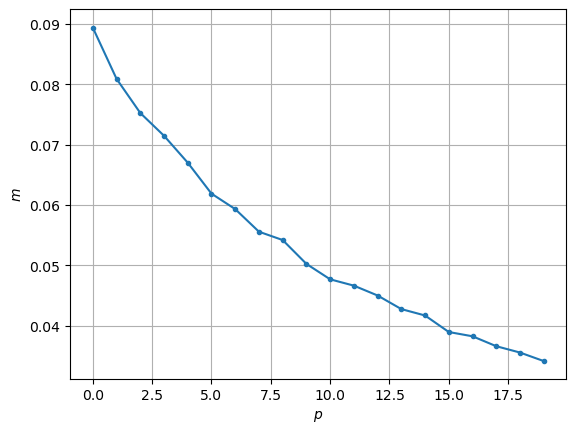

In [23]:
#plt.plot(x, m, '.', label=f'$p=${p[i]}')
plt.errorbar(x, m, err,fmt='.-')
#plt.legend()
plt.xlabel('$p$')
plt.ylabel('$m$')
plt.grid()
#plt.savefig('slike/masa_p.pdf')

In [26]:
m=[]
p=np.logspace(3, 7, 100)
napaka=[]
for i in p:
    mi, n = masa(i, 0)
    m.append(mi)
    napaka.append(n)

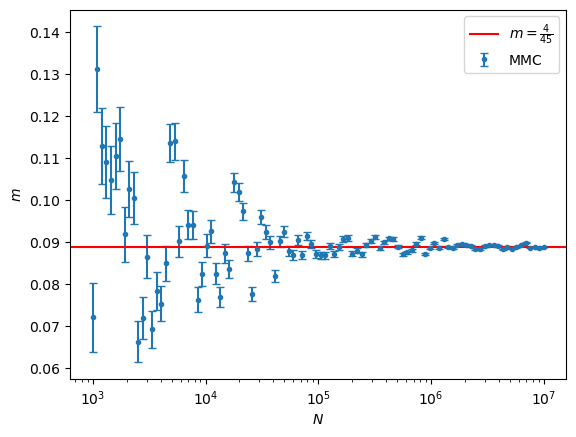

In [28]:
plt.errorbar(p, m,napaka, fmt='.',capsize=3,label='MMC')
plt.axhline(4/45,color='r',label='$m=\\frac{4}{45}$')
plt.xscale('log')
plt.legend()
plt.xlabel('$N$')
plt.ylabel('$m$')
#plt.savefig('slike/masa_N.pdf')

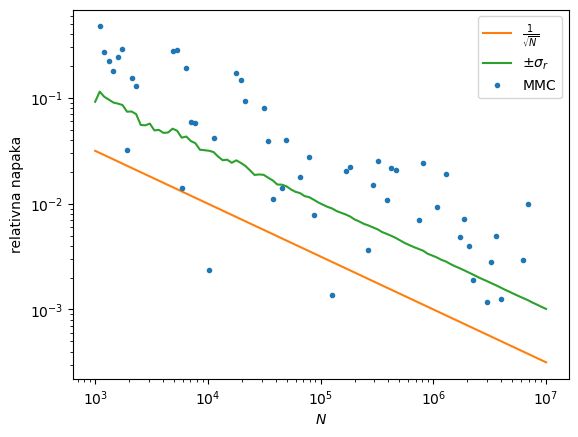

In [42]:
plt.errorbar(p,(np.array(m)-4/45)/(4/45),fmt='.',capsize=3, label='MMC')
plt.plot(p, 1/np.sqrt(p),label='$\\frac{1}{\sqrt{N}}$')
plt.plot(p,np.array(napaka)/(4/45),label='$\pm\sigma_r$')
plt.xscale('log')
plt.yscale('log')
plt.ylabel('relativna napaka')
plt.xlabel('$N$')
plt.legend()
#plt.savefig('slike/masa_relat_napaka.pdf')

In [8]:
def masa_iter(p=0): #oktant poenostavitev za eno iteracijo
    x = np.random.random()
    y = np.random.random()
    z = np.random.random()
    r = np.sqrt(x) + np.sqrt(y) + np.sqrt(z)
    if r <= 1: #znotraj
        N = 1
        m = r**p
        napaka = (r**p)**2
    else:
        N = 1
    return N,m,napaka

In [43]:
m=[]
napaka=[]
N=10000
N_=1000
for i in range(1000):
    mi, n = masa(N, 0)
    m.append(mi)
    napaka.append(n)
m_=[]
napaka_=[]
for i in range(1000):
    mi, n = masa(N_, 0)
    m_.append(mi)
    napaka_.append(n)

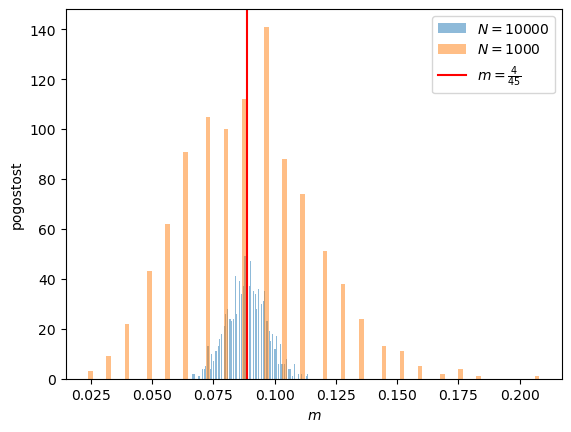

In [65]:
plt.hist(m,bins=100,label=f'$N=${N}',alpha=0.5)
plt.hist(m_,bins=100,label=f'$N=${N_}',alpha=0.5)
plt.axvline(4/45,color='r',label='$m=\\frac{4}{45}$')
plt.legend()
plt.xlabel('$m$')
plt.ylabel('pogostost')
#plt.savefig('slike/masa_porazdelitev.pdf')

# mvm

In [203]:
m=[]
p=np.logspace(3, 5, 100)
Ix=[]
Iy=[]
Iz=[]
Ixy=[]
Ixz=[]
Iyz=[]
Ip=[]
Ip_err=[]
for i in p:
    Ixi,Iyi,Izi,Ixyi,Ixzi,Iyzi,Ipi,Ip_erri = mvm(i, 0)
    m.append(mi)
    napaka.append(n)
    Ix.append(Ixi)
    Iy.append(Iyi)
    Iz.append(Izi)
    Ixy.append(Ixyi)
    Ixz.append(Ixzi)
    Iyz.append(Iyzi)
    Ip.append(Ipi)
    Ip_err.append(Ip_erri)
# Ix=np.array(Ix)
# Iy=np.array(Iy)
# Iz=np.array(Iz)
# Ixy=np.array(Ixy)
# Ixz=np.array(Ixz)
# Iyz=np.array(Iyz)
# Ip=np.array(Ip)
# Ip_err=np.array(Ip_err)

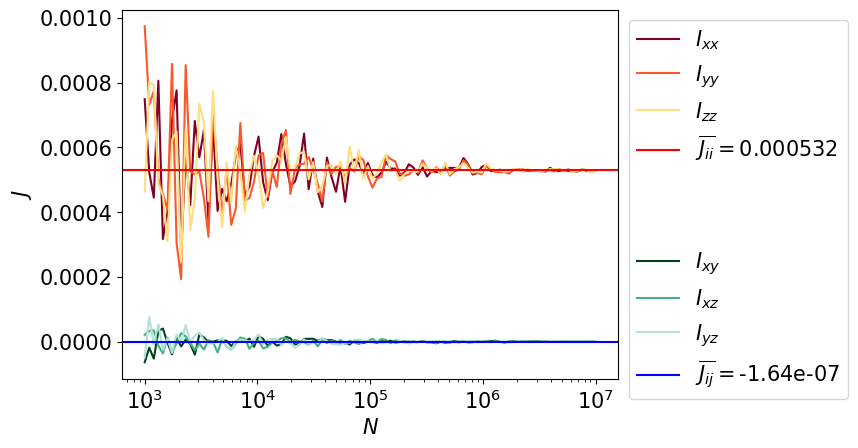

In [204]:
cmap = plt.get_cmap('YlOrRd_r')
plt.plot(p,Ix,label='$I_{xx}$',color=cmap(1))
plt.plot(p,Iy,label='$I_{yy}$',color=cmap(100))
plt.plot(p,Iz,label='$I_{zz}$',color=cmap(200))
plt.axhline(np.average(Ix+Iy+Iz),color='r',label=f'$\\overline{{J_{{ii}}}}=${round(np.average(Ix+Iy+Iz),6)}')
plt.plot(0,0,label=' \n\n ',color='w')
cmap = plt.get_cmap('BuGn_r')
plt.plot(p,Ixy,label='$I_{xy}$',color=cmap(0))
plt.plot(p,Ixz,label='$I_{xz}$',color=cmap(100))
plt.plot(p,Iyz,label='$I_{yz}$',color=cmap(175))
#plt.errorbar(p,Ip,Ip_err, fmt='.-',label='$I_{p}$',capsize=3)
#plt.axhline(4/45,color='r',label='$m=4/45$')
plt.axhline(np.average(Ixy+Iyz+Ixz),color='b',label=f'$\\overline{{J_{{ij}}}}=${round(np.average(Ixy+Iyz+Ixz),9)}')
plt.legend(bbox_to_anchor=(1,1))
plt.xscale('log')
plt.xlabel('$N$')
plt.ylabel('$J$')
#plt.savefig('slike/mvm.pdf',bbox_inches='tight')

Text(0, 0.5, '$J$')

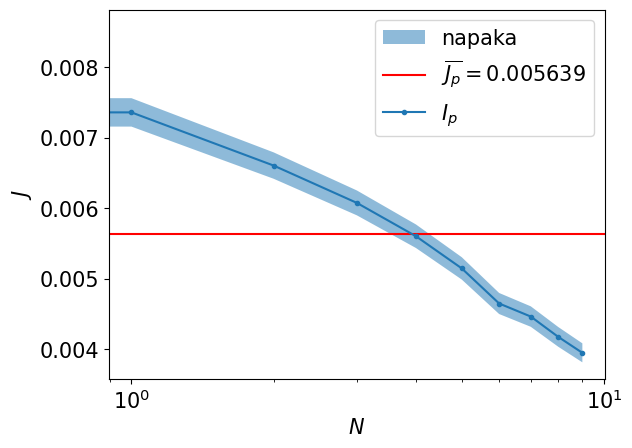

In [260]:
plt.errorbar(p,Ip, fmt='.-',label='$I_{p}$',capsize=3)
plt.fill_between(p,np.array(Ip)-np.array(Ip_err),np.array(Ip)+np.array(Ip_err), alpha=0.5, label='napaka')
#plt.axhline(4/45,color='r',label='$m=4/45$')
plt.axhline(np.average(Ip),color='r',label=f'$\\overline{{J_p}}=${round(np.average(Ip),6)}')
plt.legend()
plt.xscale('log')
plt.xlabel('$N$')
plt.ylabel('$J$')
#plt.savefig('slike/J_polarni.pdf',bbox_inches='tight')

## vpliv p

In [288]:
Ni = 1000000
m=[]
pp=np.arange(-2,0,0.2)
p=np.arange(0, 12, 2)
p=np.append(pp,p)
print(p)
napaka=[]
Ip=[]
Ip_err=[]
for i in p:
    print(i,'/',len(p))
    Ixi,Iyi,Izi,Ixyi,Ixzi,Iyzi,Ipi,Ip_erri = mvm(Ni, i)
    Ip.append(Ipi)
    Ip_err.append(Ip_erri)
    mi, n = masa(Ni, i)
    m.append(mi)
    napaka.append(n)

[-2.  -1.8 -1.6 -1.4 -1.2 -1.  -0.8 -0.6 -0.4 -0.2  0.   2.   4.   6.
  8.  10. ]
-2.0 / 16
-1.8 / 16
-1.6 / 16
-1.4000000000000001 / 16
-1.2000000000000002 / 16
-1.0000000000000002 / 16
-0.8000000000000003 / 16
-0.6000000000000003 / 16
-0.40000000000000036 / 16
-0.2000000000000004 / 16
0.0 / 16
2.0 / 16
4.0 / 16
6.0 / 16
8.0 / 16
10.0 / 16


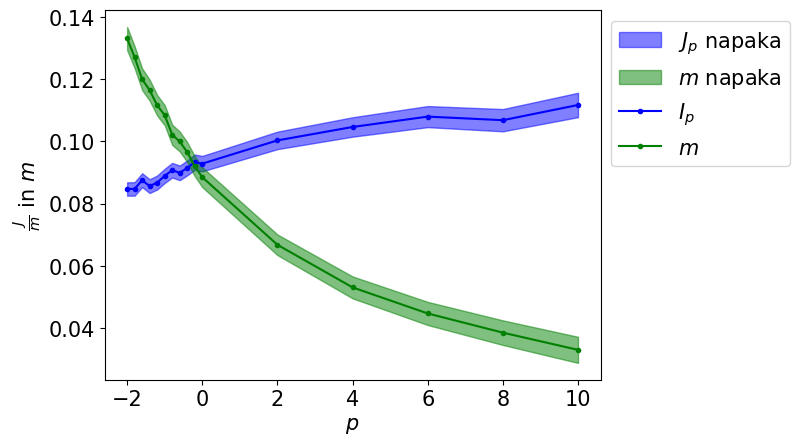

In [290]:
m=np.array(m)
napaka=np.array(napaka)
Ip=np.array(Ip)
Ip_err=np.array(Ip_err)
plt.errorbar(p,Ip/m, fmt='b.-',label='$I_{p}$')
plt.fill_between(p, (Ip-Ip_err)/m,(Ip+Ip_err)/m,color='b', alpha=0.5, label='$J_p$ napaka')
plt.errorbar(p,m, fmt='g.-',label='$m$')
plt.fill_between(p,(m-napaka/m), (m+napaka/m),color='g', alpha=0.5, label='$m$ napaka')
#plt.axhline(4/45,color='r',label='$m=4/45$')
#plt.axhline(np.average(m),color='r',label=f'$\\overline{{m}}=${round(np.average(m),6)}')
#plt.axhline(np.average(Ip/m),color='y',label=f'$\\overline{{J_p}}=${round(np.average(Ip/m),6)}')
plt.legend(bbox_to_anchor=(1,1))
#plt.xscale('log')
plt.xlabel('$p$')
plt.ylabel('$\\frac{J}{m}$ in $m$')
#plt.savefig('slike/Jp_m_vpliv_p.pdf',bbox_inches='tight')

# tež

In [298]:
m=[]
p=np.logspace(3, 6, 100)
tx=[]
ty=[]
tz=[]
tx_err=[]
napaka=[]
for i in p:
    Ixi,Iyi,Izi,Ip_erri = težišče(i, 0)
    m.append(mi)
    napaka.append(n)
    tx.append(Ixi)
    ty.append(Iyi)
    tz.append(Izi)
    tx_err.append(Ip_erri)

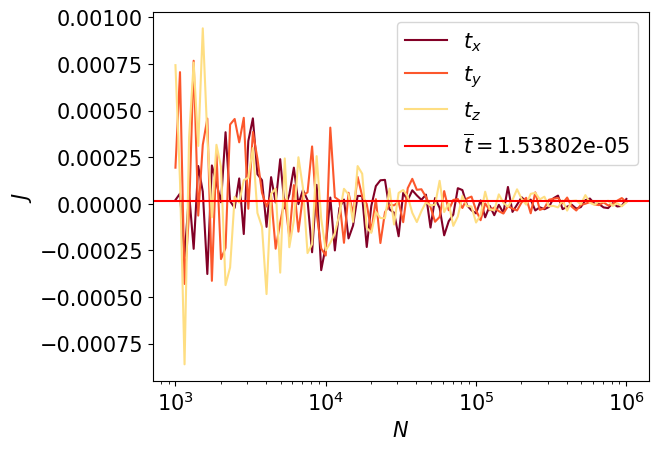

In [301]:
cmap = plt.get_cmap('YlOrRd_r')
plt.plot(p,tx,label='$t_{x}$',color=cmap(1))
plt.plot(p,ty,label='$t_{y}$',color=cmap(100))
plt.plot(p,tz,label='$t_{z}$',color=cmap(200))
plt.axhline(np.average(tx+ty+tz),color='r',label=f'$\\overline{{t}}=${round(np.average(tx+ty+tz),10)}')
plt.xscale('log')
plt.xlabel('$N$')
plt.ylabel('$J$')
plt.legend()
#plt.savefig('slike/težišče.pdf',bbox_inches='tight')

## n-dimenzij

In [75]:
def masa_n(N_max, n_dim, p=0): #oktant poenostavitev
    n = 0 #št zadetkov
    N = 0 #št klicev
    m = 0 #masa
    napaka = 0
    while N < N_max:
        r=0
        for i in range(n_dim):
            x = np.random.random()
            r+= x*x
        if r <= 1: #znotraj
            n += 1
            N += 1
            m += r**p
            napaka += (r**p)**2
        else:
            N += 1
    napaka = np.sqrt(8*napaka/N - (8*m/N)**2)/np.sqrt(N)
    return 2**n_dim*m/N, napaka
masa_n(1000000, 4,0), masa(100000,0)

C:\Users\ravni\AppData\Local\Temp\ipykernel_14988\1108284862.py:18: RuntimeWarning: invalid value encountered in sqrt
  napaka = np.sqrt(8*napaka/N - (8*m/N)**2)/np.sqrt(N)


((4.940592, nan), (0.08512, 0.0008824657817728685))

In [137]:
N=1000000
n0=np.arange(0,20,1)
val=[]
napaka=[]
for n in n0:
    p, n = masa_n(N,int(n),0)
    val.append(p)
    napaka.append(n)

C:\Users\ravni\AppData\Local\Temp\ipykernel_14988\1108284862.py:18: RuntimeWarning: invalid value encountered in sqrt
  napaka = np.sqrt(8*napaka/N - (8*m/N)**2)/np.sqrt(N)


In [138]:
#analitično
def vol(n):
    v=[1,2]
    for i in range(3,n+2):
        vi=2*np.pi/(i) * v[i-2]
        v.append(vi)
    return np.array(v)
def vol(n):
    return (np.pi**(n/2) / gamma(n/2 + 1))
n0, vol(n0)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19]),
 array([1.        , 2.        , 3.14159265, 4.1887902 , 4.9348022 ,
        5.26378901, 5.16771278, 4.72476597, 4.05871213, 3.2985089 ,
        2.55016404, 1.88410388, 1.33526277, 0.91062875, 0.59926453,
        0.38144328, 0.23533063, 0.14098111, 0.08214589, 0.0466216 ]))

Text(0, 0.5, '$V$')

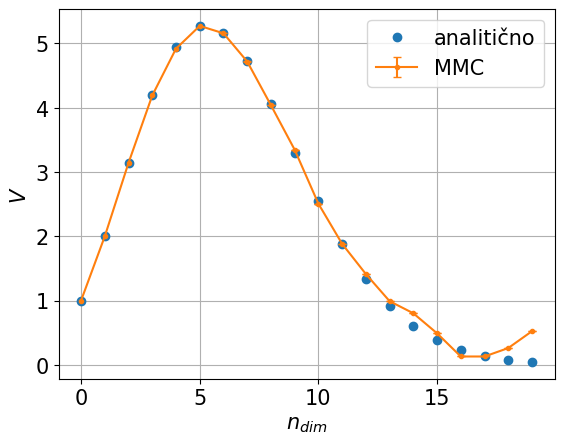

In [162]:
plt.plot(n0,vol(n0),'o',label='analitično')
plt.errorbar(n0,val,napaka,fmt='.-',label='MMC',capsize=3) #napaka ne velja za več dim?
# plt.plot(0,1, 'o',label='$V_0=1$')
# plt.plot(1,2, 'o', label='$V_1=2$')
# plt.plot(2, np.pi,'o',label='$V_2=\pi$')
# plt.plot(3, 4/3*np.pi,'o',label='$V_3=\\frac{4 \pi}{3}$')
plt.grid()
plt.legend()
plt.xlabel('$n_{dim}$')
plt.ylabel('$V$')
#plt.savefig('slike/vol_ndim.pdf',bbox_inches='tight')

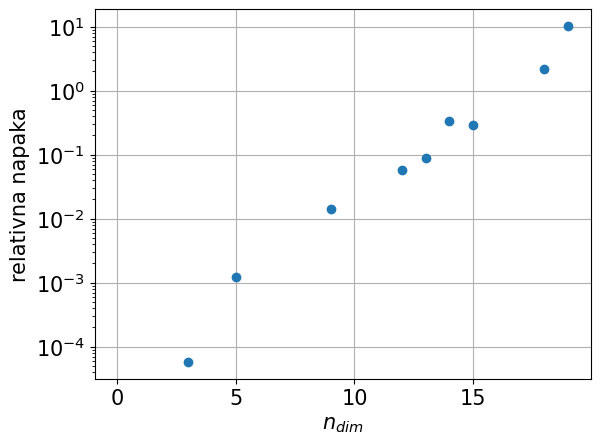

In [160]:
plt.plot(n0, (val-vol(n0))/vol(n0),'o')
plt.grid()
plt.xlabel('$n_{dim}$')
plt.yscale('log')
plt.ylabel('relativna napaka')
#plt.savefig('slike/vol_ndim_napaka.pdf',bbox_inches='tight')